In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emcee
import corner

from scipy.optimize import minimize
from scipy.stats import gaussian_kde
from scipy.interpolate import UnivariateSpline

from sklearn.utils import resample

from astropy.coordinates import SkyCoord
from astropy.visualization.wcsaxes import SphericalCircle
import astropy.units as u

import time
import tqdm as tqdm
from multiprocessing import Pool
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(123)

[ 0.00142689 -0.04548921  0.36606062  1.        ]


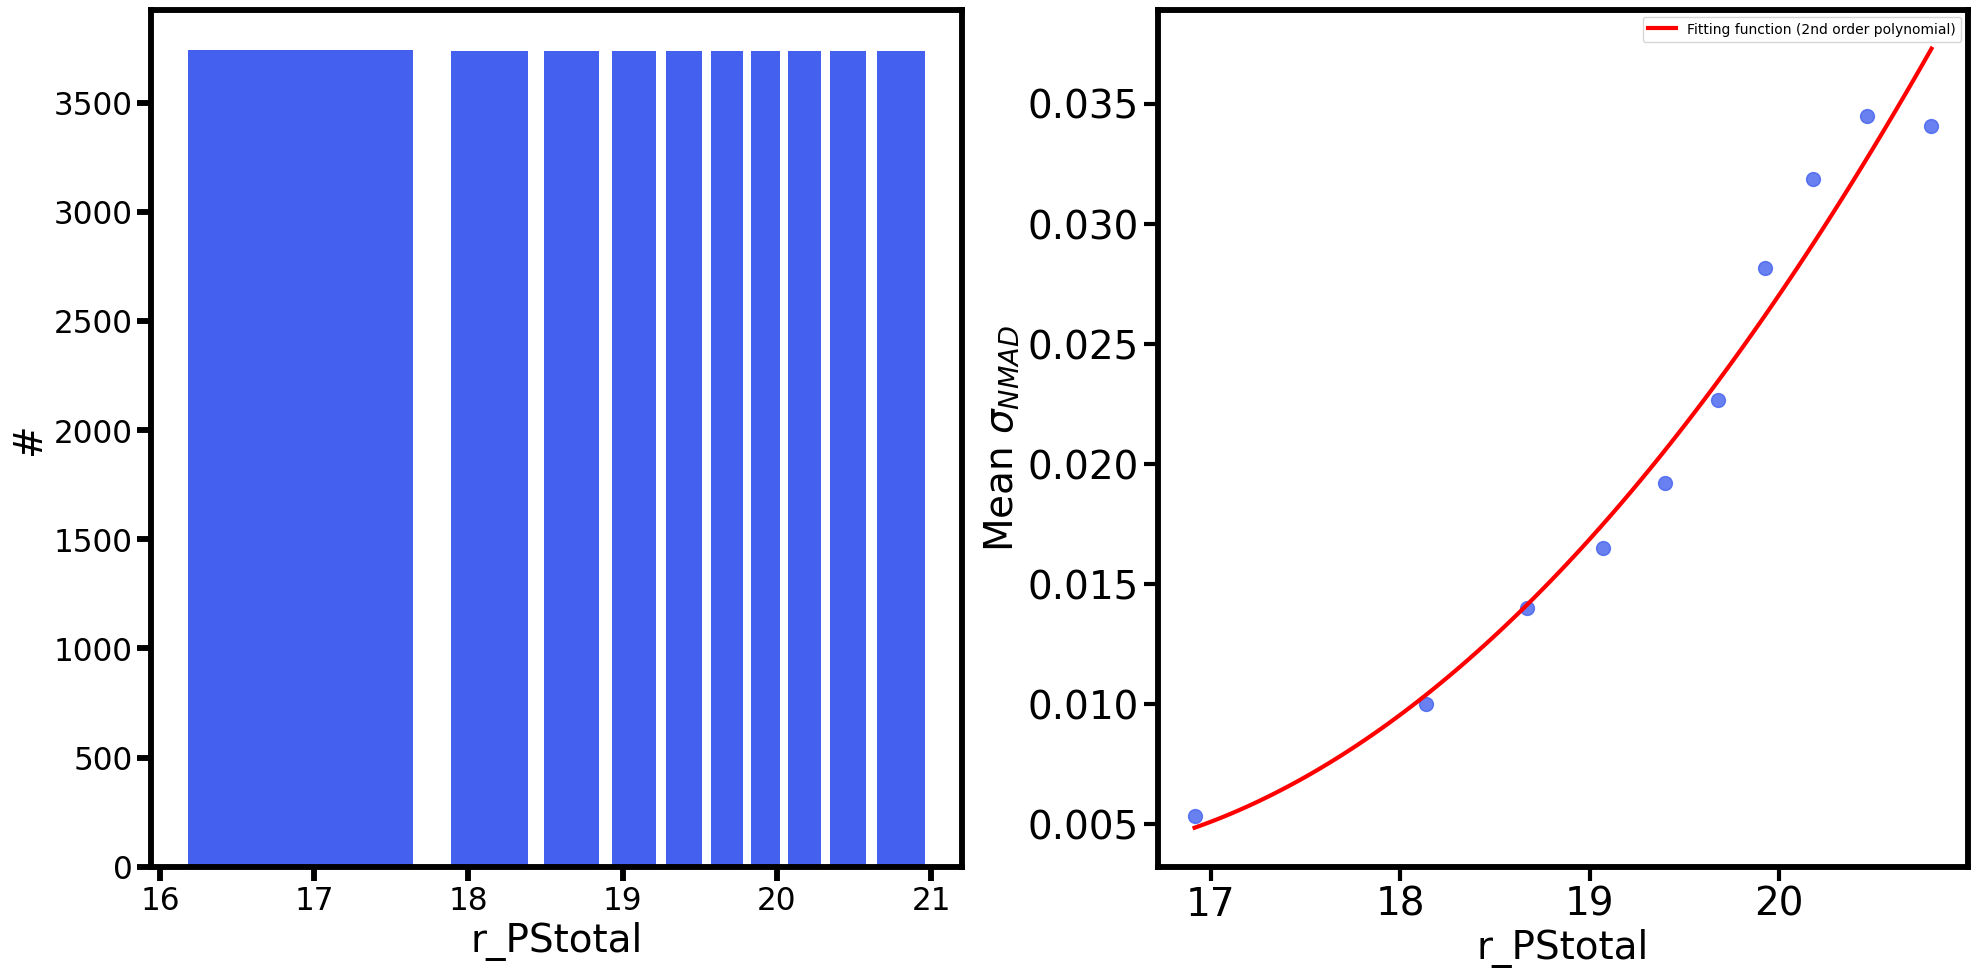

In [2]:
from galaxy_cluster_membership import *

In [3]:
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import rc, rcParams
f = 0.8

fontsize = 35 * f
labelsize = 20 * f

rc("xtick", labelsize=fontsize * f)
rc("ytick", labelsize=fontsize * f)
rcParams["axes.linewidth"] = 5.3 * f
rcParams["xtick.major.width"] = 5.3 * f
rcParams["xtick.minor.width"] = 5.3 * f
rcParams["ytick.major.width"] = 5.3 * f
rcParams["ytick.minor.width"] = 5.3 * f
rcParams["xtick.major.size"] = 12.5 * f
rcParams["xtick.minor.size"] = 6.5 * f
rcParams["ytick.major.size"] = 12.5 * f
rcParams["ytick.minor.size"] = 6.5 * f

font = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 50 * f,
        }


cm1 = plt.cm.get_cmap('jet')
cm2 = plt.cm.get_cmap('rainbow')
cm3 = plt.cm.get_cmap('gnuplot2')
cm4 = plt.cm.get_cmap('Pastel2')
cm5 = plt.cm.get_cmap('Set3')
cm6 = plt.cm.get_cmap('gist_rainbow')

color_values = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
colors1 = [cm1(value) for value in color_values]
colors2 = [cm2(value) for value in color_values]
colors3 = [cm3(value) for value in color_values]
colors4 = [cm4(value) for value in color_values]
colors5 = [cm5(value) for value in color_values]
colors6 = [cm6(value) for value in color_values]

### Load data

In [43]:
i_mock = 8

t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
members = t["phot_member"] == 1
ras = np.array(t["RA"][members]) #deg
decs = np.array(t["DEC"][members]) #deg
zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
zs = np.array(t["z_app"][members]) 


x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]


side = min(max(ras) - min(ras), max(decs) - min(decs))
all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})
# x0 = np.mean(ras)
# y0 = np.mean(decs)

In [44]:
#Distribuição cumulativa observada
Rp = clustercentric_distance(ras, decs, x0, y0)
Hz, Rcz = np.histogram(Rp, bins=100, density=True)
dR = Rcz[1] - Rcz[0]
Fz = np.cumsum(Hz)*dR
R = Rcz[1:]

### Define functions

In [15]:
def Sersic_density(R, params):
    '''
    Sersic profile with an exponential cutoff plus a constant field density
    '''

    Sigma0, R0, alpha, Rt, tau, Sigma_field = params

    Sigma = Sigma0 * np.exp(-(R/R0)**alpha) * np.exp(-(R/Rt)**tau) + Sigma_field

    return Sigma


def Sersic_density_cumulative(R, dR, params):
    '''
    Sersic profile with an exponential cutoff plus a constant field density
    '''

    Sigma0, R0, alpha, Rt, tau, Sigma_field = params

    Sigma_c = Sigma0 * np.exp(-(R/R0)**alpha) * np.exp(-(R/Rt)**tau)

    cum_f = np.pi * Sigma_field * R**2
    #Polar integral of Sigma_c to obtain the cumulative density profile
    cum_c = 2*np.pi*np.array([np.sum(Sigma_c[R < R[i]] * R[R < R[i]] * dR) for i in range(len(R))])
    cum_dens = cum_f + cum_c

    return cum_dens


def splashback_radius(R, r200_deg, best_params, model_density):
    '''
    Compute the 2D splashback radius (Rsp)
    The 3D r_sp can be obtained by r_sp = sqrt(pi/2) * Rsp (More et al. 2016, see also Lucas's paper (Gabriel-Silva & Sodré 2025))
    '''

    Sigma_ = model_density(R, best_params)

    #This is like doing dlog(Sigma_)/dlog(R) = R/Sigma_ * dSigma_/dR
    #s is for smoothing the function. The final result depends on the value of s, but for lack of further information we set s=None.
    Sigma_spline = UnivariateSpline(R, Sigma_, s=None)
    gamma = R/Sigma_ * Sigma_spline.derivative()(R)

    #I am limiting the search for the minimum of gamma to R < 4*r200, 
    #because after that the profile is dominated by the background and it creates a false minimum in gamma
    Rsp = R[np.argmin(gamma[R/r200_deg < 4])]

    return Rsp, gamma


def ellipticity(clust_dist, Rsp, ras, decs, ra0, dec0, cartesian=False):
    '''
    Compute cluster's ellipticity; see Shin et al. (2018) for reference. 
    '''

    select_aperture = clust_dist < Rsp

    #RA and Dec needs to be centered on the origin for the ellipticity calculation to make sense
    xi = ras[select_aperture] - ra0
    yi = decs[select_aperture] - dec0

    if cartesian:
        #The difference between using cartesian or spherical coordinates for the 
        #ellipticity calculation is small (difference in 3rd decimal place) for small angles (clusters' angular sizes are small)
        x_cartesian = np.cos(np.deg2rad(ras[select_aperture])) * np.cos(np.deg2rad(decs[select_aperture]))
        y_cartesian = np.cos(np.deg2rad(ras[select_aperture])) * np.sin(np.deg2rad(decs[select_aperture]))
        z_cartesian = np.sin(np.deg2rad(decs[select_aperture]))

        xi = x_cartesian - np.mean(x_cartesian)
        yi = z_cartesian - np.mean(z_cartesian)

    wi = 1 / (xi**2 + yi**2)
    Ixx = np.sum(xi**2 * wi) / np.sum(wi)
    Iyy = np.sum(yi**2 * wi) / np.sum(wi)
    Ixy = np.sum(xi * yi * wi) / np.sum(wi)

    e1 = (Ixx - Iyy) / (Ixx + Iyy)
    e2 = (2 * Ixy) / (Ixx + Iyy)
    e = np.sqrt(e1**2 + e2**2)

    return e


In [5]:
def log_likelihood(params, R, dR, data): 
    
    model_density = Sersic_density(R, dR, params)
    residuals = data - model_density
    sigma = np.sqrt(1/len(data) * (residuals)**2)
    
    # Assuming Gaussian noise, the log likelihood is proportional to the square of residuals
    return -0.5 * np.sum(residuals**2/sigma**2 + np.log(2 * np.pi * sigma**2)) * 0.2


# Define prior distributions (simple uniform priors in this case)
def log_prior(params, r200_deg):
    Sigma0, R0, alpha, Rt, tau, Sigma_field = params
    
    if 0 < Sigma0 < 100 and 0 < R0 < 10*r200_deg and 0 < alpha < 20 and 0 < Sigma_field < 100 and 0 < Rt < 10*r200_deg and 0 < tau < 10:
        return 0.0  # log(1) = 0, uniform prior
    return -np.inf  # log(0) = -inf, to reject parameters outside these ranges
    

def log_probability(params, R, dR, data, r200_deg):
    lp = log_prior(params, r200_deg)
    if not np.isfinite(lp):
        return -np.inf
    return lp + log_likelihood(params, R, dR, data)


def run_mcmc(nsteps, nwalkers, guess, log_probability, args, moves, multi_process=False):
    '''
    Wrapper for running the MCMC with emcee, with or without multiprocessing.

    Parameters
    ----------
    nsteps : int
        Number of MCMC steps to run.
    guess : array-like
        Initial guess for the parameters.
    log_probability : function
        Function to compute the log-probability.
    args : tuple
        Additional arguments to pass to the log-probability function.
    moves : emcee.moves object
        Move strategy for the MCMC sampler.
    multi_process : bool, optional
        Whether to use multiprocessing. Default is False.
    '''

    pos = guess + 1e-4 * np.random.randn(nwalkers, len(guess))
    _, ndim = pos.shape

    if multi_process == False:
        sampler = emcee.EnsembleSampler(
            nwalkers, 
            ndim, 
            log_probability, 
            args=args,
            moves=moves
        )
        sampler.run_mcmc(pos, nsteps, progress=True);

    elif multi_process == True:
        with Pool(processes=nwalkers) as pool:
            sampler = emcee.EnsembleSampler(
                nwalkers,
                ndim,
                log_probability,
                args=args,
                pool=pool
                )
            
            start = time.time()

            sampler.run_mcmc(pos, nsteps, progress=True)
            
            end = time.time()
            multi_time = end - start
            print("Multiprocessing took {0:.1f} seconds".format(multi_time))

    return sampler

In [6]:
def chi_squared(params, R, dR, observed_density):
    modeled_density = Sersic_density(R, dR, params)
    return np.sum((observed_density - modeled_density)**2)


def fit_cumulative(R, dR, data, init, r200_deg):
    
    bounds = [
        (0, 100), #Sigma0
        (0, 5.0*r200_deg), #R0
        (0, 20), #alpha
        (0, 10*r200_deg), #Rt
        (0, 10), #tau
        (0, 20) #Sigma_field
    ]

    # init = [1, r200_deg/2, 1, 0.5]

    fit = minimize(chi_squared, init, args=(R, dR, data), method='Nelder-Mead', bounds=bounds)
    return fit


def bootstrap_fit(data, init, r200_deg, x0, y0, B=1000):
    estimates = np.zeros((B, 9))  # 5 model parameters + chi2 + Rsp + ellipticity

    bounds = [
        (0, 100), #Sigma0
        (0, 5.0*r200_deg), #R0
        (0, 20), #alpha
        (0, 10*r200_deg), #Rt
        (0, 10), #tau   
        (0, 20) #Sigma_field
    ]

    for b in tqdm.tqdm(range(B)):
        resampled_data = resample(data)

        x = resampled_data["ras"] 
        y = resampled_data["decs"]

        #I am letting the cluster's center (x0, y0) fixed
        Rp = clustercentric_distance(x, y, x0, y0)
        Hz, Rcz = np.histogram(Rp, bins=100, density=True)
        dR = Rcz[1] - Rcz[0]
        Fz = np.cumsum(Hz)*dR
        R = Rcz[1:]

        # try:
        fit_b = minimize(chi_squared, init, args=(R, dR, Fz), method='Nelder-Mead', bounds=bounds)

        Rsp = splashback_radius(R, dR, fit_b.x, Sersic_density)
        e = ellipticity(Rp, Rsp, x, y, x0, y0)


        # if fit_b.success:
        estimates[b, 0] = fit_b.x[0]  # Sigma0
        estimates[b, 1] = fit_b.x[1]  # R0
        estimates[b, 2] = fit_b.x[2]  # alpha
        estimates[b, 3] = fit_b.x[3]  # Rt
        estimates[b, 4] = fit_b.x[4]  # tau
        estimates[b, 5] = fit_b.x[5]  # Sigma_field
        estimates[b, 6] = chi_squared(fit_b.x, R, dR, Fz)  # chi2
        estimates[b, 7] = Rsp  # Rsp
        estimates[b, 8] = e    # ellipticity
        # except:
        #     continue
    
    return pd.DataFrame(estimates, columns=["Sigma0", "R0", "alpha", "Rt", "tau", "Sigma_field", "chi2", "Rsp", "e"])

### Trying some mcmc trick

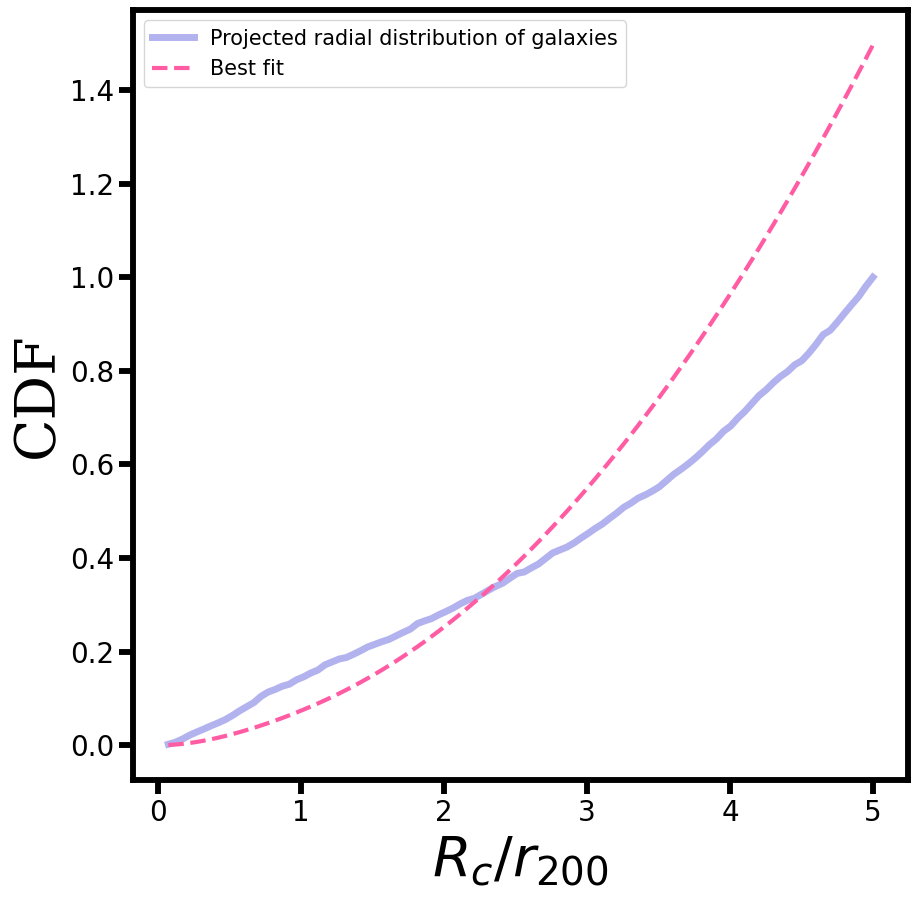

In [9]:
cum_dens = Sersic_density(R, dR, [1, r200_deg/2, 1, 1*r200_deg, 4, 1.0])

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

In [ ]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

first_guess = np.array([1, r200_deg/2, 1, 1*r200_deg, 4, 1.0]) #initial guess for [Sigma0, R0, alpha, Rt, tau, Sigma_field]
# first_guess = second_guess
# pos = first_guess + 1e-4 * np.random.randn(nwalkers, len(first_guess))

sampler = run_mcmc(nsteps, 
                    first_guess,
                    log_probability, 
                    args=(R, dR, Fz), 
                    moves=emcee.moves.StretchMove(),
                    multi_process=False)

samples = sampler.get_chain()

#flat = flatten the chains across the ensample
#discard = discard the burn_in phase
#thin = "thins" the sample every N iterations (for instance 15)
flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
means = np.mean(flat_samples, axis=0)

  0%|          | 0/10000 [00:00<?, ?it/s]

100%|██████████| 10000/10000 [03:17<00:00, 50.56it/s]


2.5663590251997714
0.2687452055715186
1.8140395527379936
0.17095738716049869
4.294151890077936
0.563776757456644


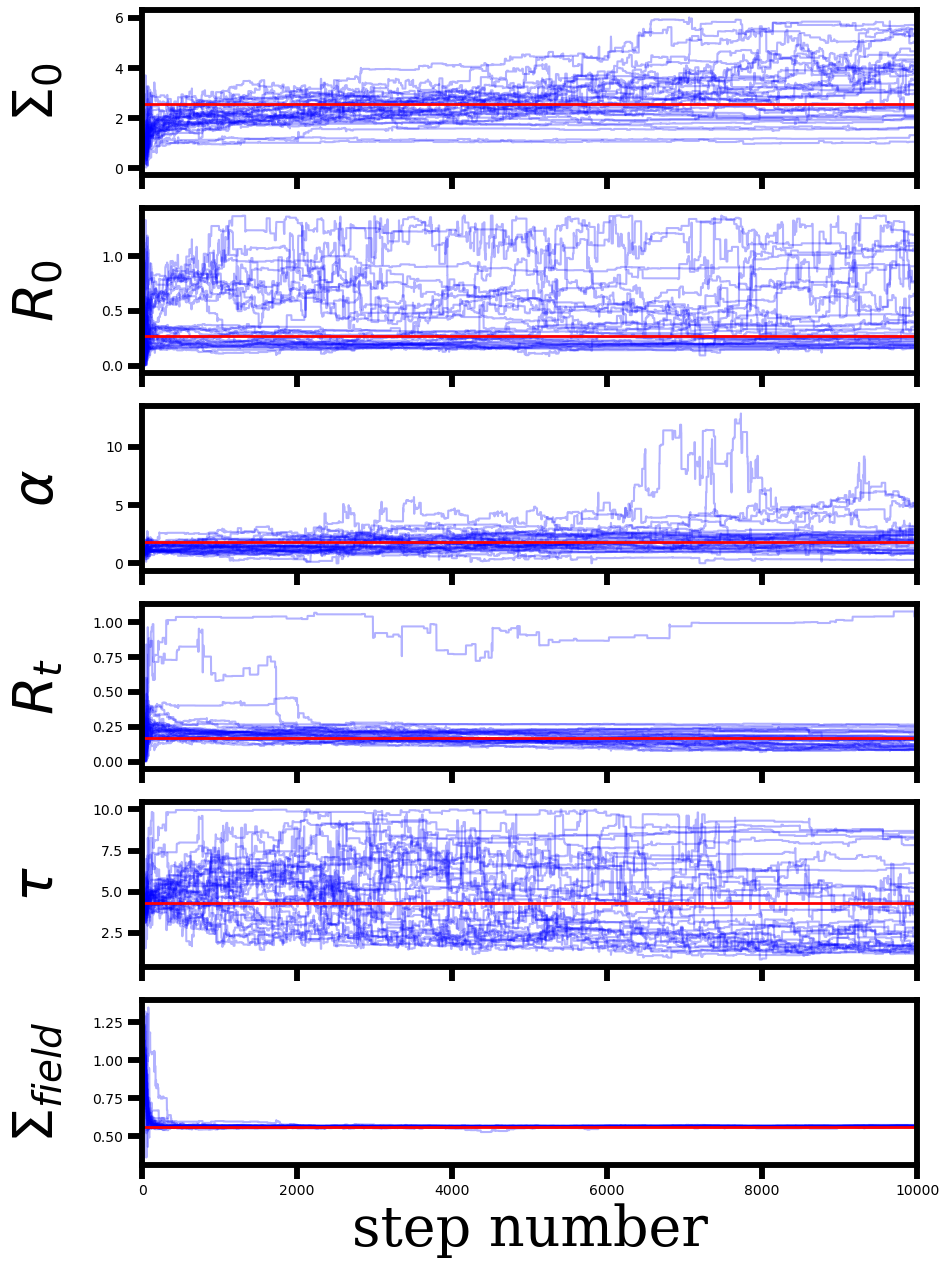

In [44]:
labels = [r"$\Sigma_0$", r"$R_0$", r"$\alpha$", r"$R_t$", r"$\tau$", r"$\Sigma_{field}$"]


fig, axes = plt.subplots(6, figsize=(10, 15), sharex=True)
# Styling
rcParams["font.size"] = 10
rcParams["axes.labelsize"] = 10
rcParams["xtick.labelsize"] = 10
rcParams["ytick.labelsize"] = 10

for i in range(len(first_guess)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "blue", alpha=0.3)
    ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i], fontdict=font)
    ax.yaxis.set_label_coords(-0.1, 0.5)

    print(np.median(samples[int(burn_in*nsteps):, :, i]))

axes[-1].set_xlabel("step number", fontdict=font);

# plt.savefig("../figures/elliptical_profiles/SIS_SISell_NFW_NFWell_17-06-2025/trace_plot_mcmc_mock{}_model{}_{}iterations.png".format(i_mock, model, nsteps),
#                                      dpi='figure', format='png')

#Guess after running the mcmc (median of parameters with 20% burn-in)
second_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 6)])

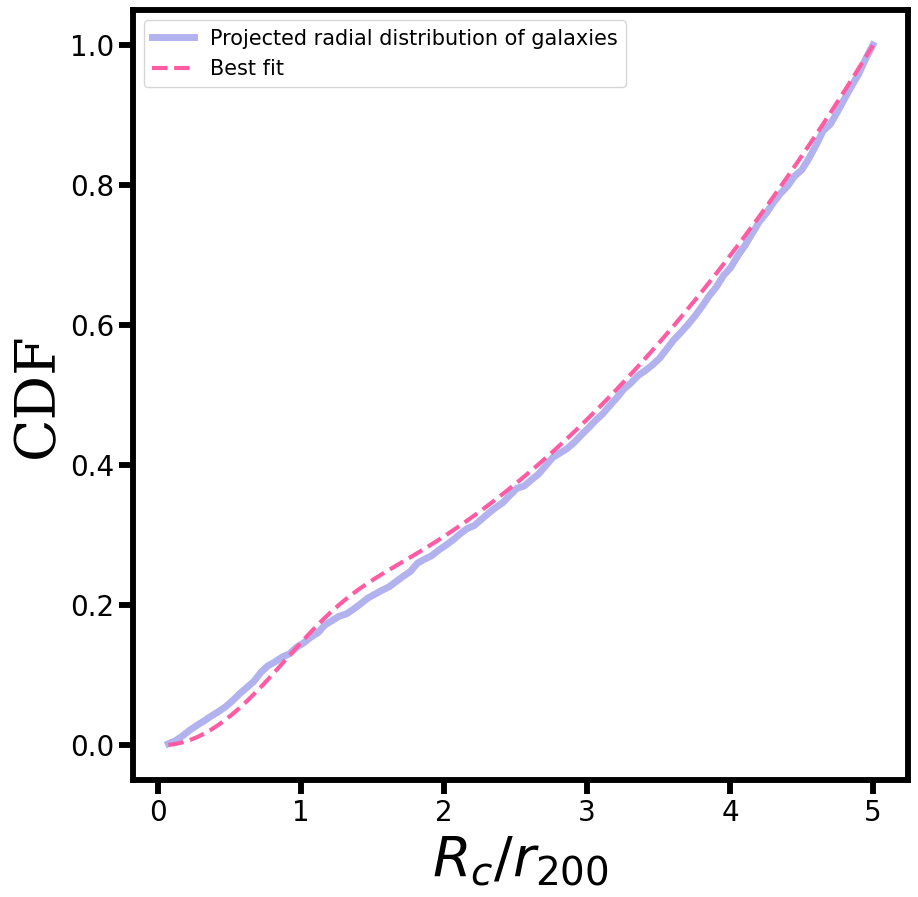

In [12]:
cum_dens = Sersic_density(R, dR, second_guess)

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

### Minimizing chi² and doing bootstrap

In [23]:
fit = fit_cumulative(R, dR, Fz, init=second_guess)
Rsp = splashback_radius(R, dR, fit.x, Sersic_density)
e = ellipticity(Rp, Rsp, ras, decs, x0, y0)

print("Fitted parameters:")
for p_value, p_name in zip(fit.x, ["Sigma0", "R0", "alpha", "Rt", "tau", "Sigma_field"]):
    print(p_name + " =", p_value)

print("R0/r200 = {:.3f}".format(fit.x[1]/r200_deg))

print()
print("Rsp = {:.3f} deg = {:.3f} R200".format(Rsp, Rsp/r200_deg))
# print("Rsp = {:.3f} R200".format(Rsp/r200_deg))
print("Ellipticity e = {:.3f}".format(e))

Fitted parameters:
Sigma0 = 8.438631512718416
R0 = 0.4473742154147353
alpha = 2.1627122598834276
Rt = 0.05720829576748787
tau = 1.0386512541831179
Sigma_field = 0.5642817342403066
R0/r200 = 3.258

Rsp = 0.153 deg = 1.117 R200
Ellipticity e = 0.121


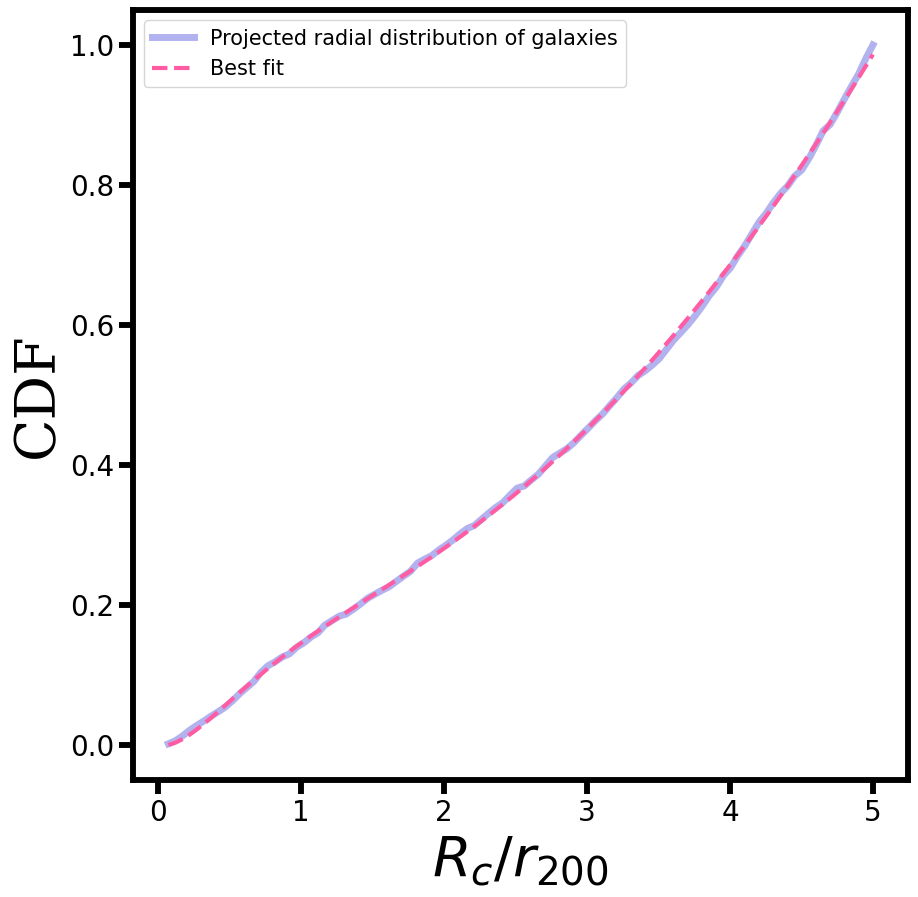

In [24]:
cum_dens = Sersic_density(R, dR, fit.x)

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

In [25]:
# Run bootstrap
t0 = time.time()
nboot = 1000
boot_results = bootstrap_fit(all_galaxies, init=fit.x, B=nboot)
print("Bootstrap time taken:", time.time() - t0)

100%|██████████| 1000/1000 [38:15<00:00,  2.30s/it] 

Bootstrap time taken: 2295.8936417102814


In [26]:
# Remove outliers
z = boot_results
for col in boot_results.columns:
    Q1 = boot_results[col].quantile(0.25)
    Q3 = boot_results[col].quantile(0.75)
    IQR = Q3 - Q1
    z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
    print("Remaining samples after outlier removal:", len(z))

boot_results_outliers_removed = z

Remaining samples after outlier removal: 980
Remaining samples after outlier removal: 871
Remaining samples after outlier removal: 769
Remaining samples after outlier removal: 731
Remaining samples after outlier removal: 714
Remaining samples after outlier removal: 707
Remaining samples after outlier removal: 670
Remaining samples after outlier removal: 668
Remaining samples after outlier removal: 664


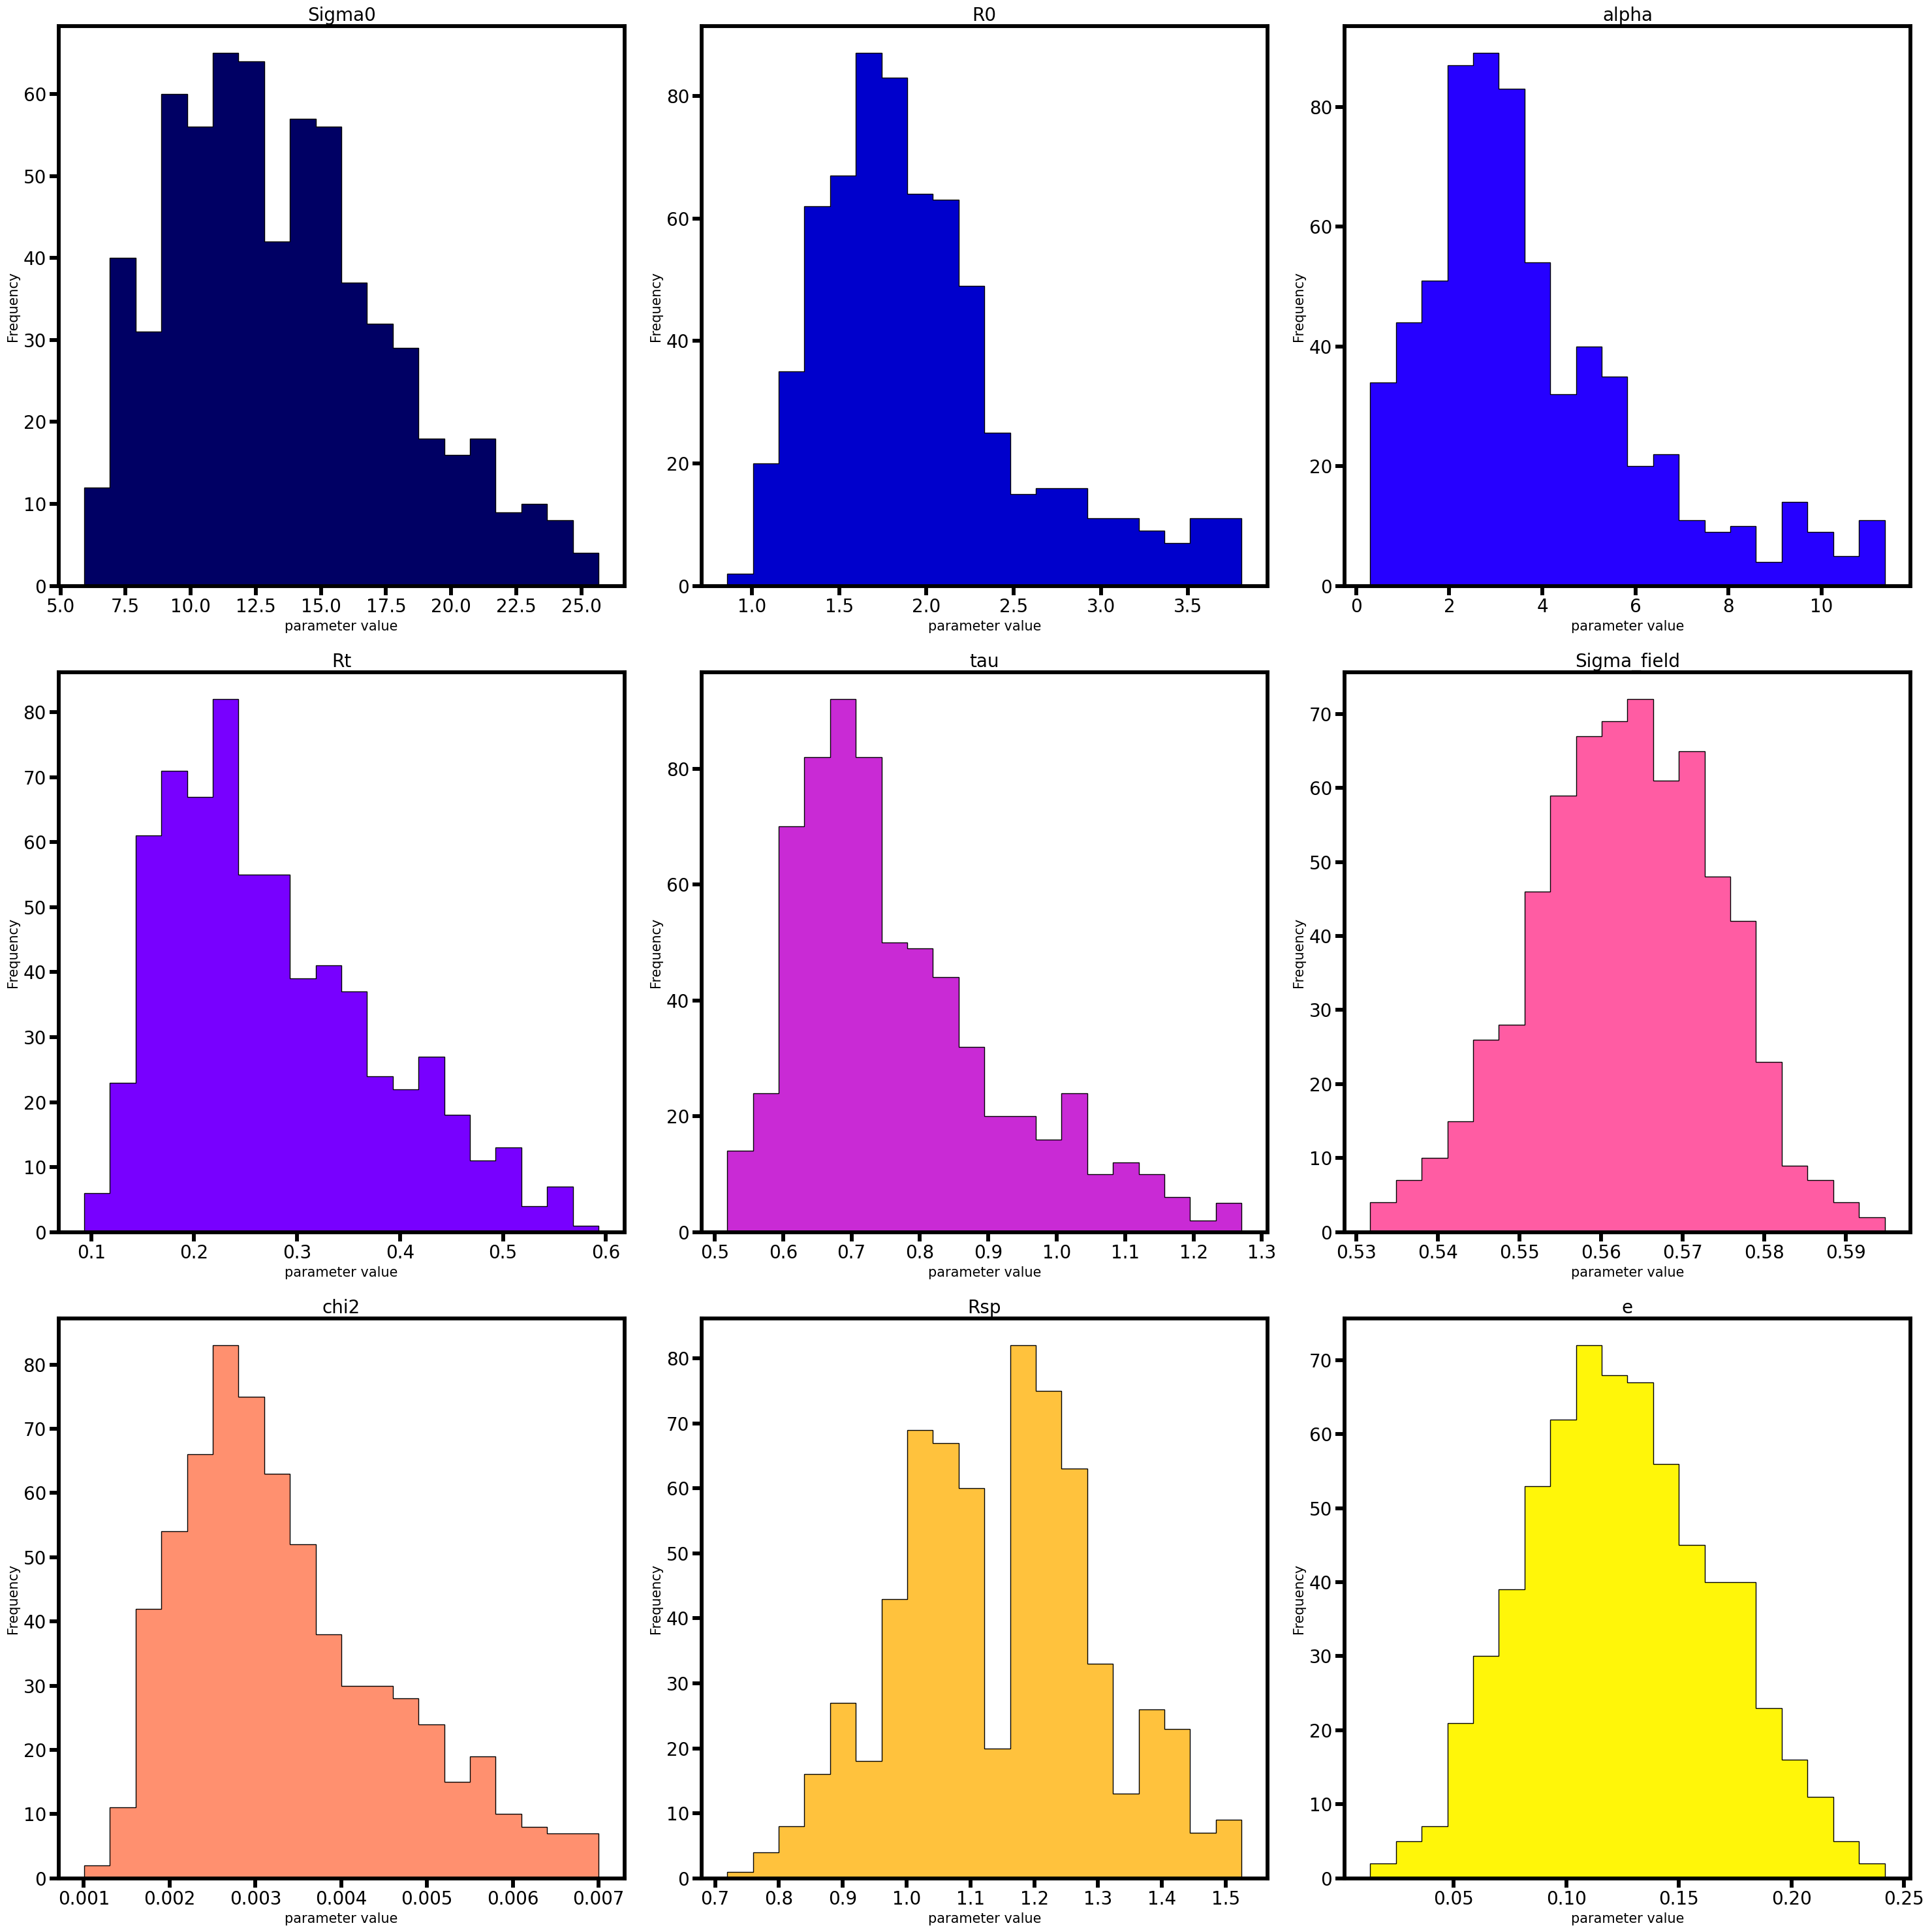

In [37]:
# Plot parameter distributions
plt.figure(figsize=(30, 30))
for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
    plt.subplot(3, 3, i+1)
    if (col == "R0") | (col == "Rt") | (col == "Rsp"):
        plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
    else:
        plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
    plt.title(col, fontsize=20) 
    plt.xlabel("parameter value", fontsize=15)
    plt.ylabel("Frequency", fontsize=15)
plt.tight_layout()

# plt.savefig("../figures/elliptical_profiles/boostrap_results/Sersic/boostrap_parameter_distribution_mock{}.pdf".format(i_mock), dpi='figure', format='pdf')

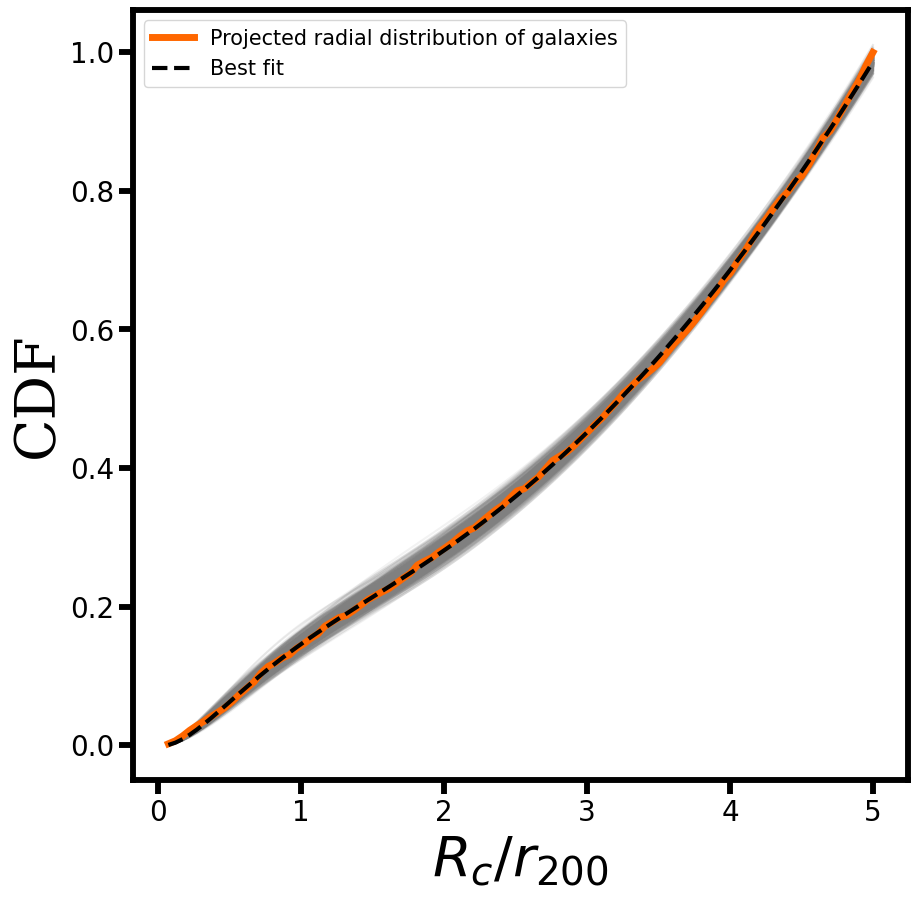

In [38]:
# cum_dens = Sersic_density(R, dR, fit.x)

fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   

ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)

for _, row in boot_results_outliers_removed.iterrows():
    params = row[:6].values
    cum_model = Sersic_density(R, dR, params)
    ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

ax.legend(fontsize=15)

### Running in a loop (mock)

In [ ]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

first_guess = np.array([1, r200_deg/2, 1, 1*r200_deg, 4, 1.0]) #initial guess for [Sigma0, R0, alpha, Rt, tau, Sigma_field], same for all clusters
labels = [r"$\Sigma_0$", r"$R_0$", r"$\alpha$", r"$R_t$", r"$\tau$", r"$\Sigma_{field}$"]

i_mock_list = []
Sigma0_list = []
R0_list = []
R0_r200_list = []
alpha_list = []
Rt_list = []
tau_list = []
Sigma_field_list = []
Rsp_list = []
e_list = []   


for i_mock in np.arange(50):

    print("COMPUTING FOR MOCK CLUSTER", i_mock)

    t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
    members = t["phot_member"] == 1
    ras = np.array(t["RA"][members]) #deg
    decs = np.array(t["DEC"][members]) #deg
    zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
    zs = np.array(t["z_app"][members]) 


    x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
    y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
    r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
    r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
    m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
    z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]


    side = min(max(ras) - min(ras), max(decs) - min(decs))
    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    
    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, x0, y0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    #======================================
    #GUESSING PARAMETERS WITH MCMC
    #======================================

    sampler = run_mcmc(nsteps, 
                       nwalkers,
                       first_guess,
                       log_probability, 
                        args=(R, dR, Fz), 
                        moves=emcee.moves.StretchMove(),
                        multi_process=False)

    samples = sampler.get_chain()

    #flat = flatten the chains across the ensample
    #discard = discard the burn_in phase
    #thin = "thins" the sample every N iterations (for instance 15)
    flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
    means = np.mean(flat_samples, axis=0)


    fig, axes = plt.subplots(6, figsize=(10, 15), sharex=True)
    # Styling
    rcParams["font.size"] = 10
    rcParams["axes.labelsize"] = 10
    rcParams["xtick.labelsize"] = 10
    rcParams["ytick.labelsize"] = 10

    for i in range(len(first_guess)):
        ax = axes[i]
        ax.plot(samples[:, :, i], "blue", alpha=0.3)
        ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
        ax.set_xlim(0, len(samples))
        ax.set_ylabel(labels[i], fontdict=font)
        ax.yaxis.set_label_coords(-0.1, 0.5)

        print(np.median(samples[int(burn_in*nsteps):, :, i]))

    axes[-1].set_xlabel("step number", fontdict=font);

    #Guess after running the mcmc (median of parameters with 20% burn-in)
    second_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 6)])

    plt.savefig("../figures/elliptical_profiles/bootstrap_results_22-01-2026/Sersic/trace_plot_mcmc_mock{}.png".format(i_mock),
                                         dpi='figure', format='png')

    #======================================
    #MINIMIZING CHI2 TO FIND BEST FIT
    #======================================
    fit = fit_cumulative(R, dR, Fz, init=second_guess)
    Rsp = splashback_radius(R, dR, fit.x, Sersic_density)
    e = ellipticity(Rp, Rsp, ras, decs, x0, y0)

    cum_dens = Sersic_density(R, dR, fit.x)

    # Run bootstrap
    t0 = time.time()
    nboot = 1000
    boot_results = bootstrap_fit(all_galaxies, init=fit.x, B=nboot)
    print("Bootstrap time taken:", time.time() - t0)
    boot_results.to_csv("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/boot_results_mock{}.csv".format(i_mock), index=False)


    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/boot_results_outliers_removed_mock{}.csv".format(i_mock), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(30, 30))
    for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
        plt.subplot(3, 3, i+1)
        if (col == "R0") | (col == "Rt") | (col == "Rsp"):
            plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        else:
            plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        plt.title(col, fontsize=20) 
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/elliptical_profiles/bootstrap_results_22-01-2026/Sersic/boostrap_parameter_distribution_mock{}.png".format(i_mock), dpi='figure', format='png')


    # Plot cumulative density fit and bootstrap results
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)   
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel("CDF", fontdict=font)

    for _, row in boot_results_outliers_removed.iterrows():
        params = row[:6].values
        cum_model = Sersic_density(R, dR, params)
        ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

    ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
    ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

    ax.legend(fontsize=15)
    plt.savefig("../figures/elliptical_profiles/bootstrap_results_22-01-2026/Sersic/cumulative_density_fit_mock{}.png".format(i_mock), dpi='figure', format='png')


    #SAVING BEST FIT PARAMETERS
    i_mock_list.append(i_mock)
    Sigma0_list.append(fit.x[0])
    R0_list.append(fit.x[1]) #deg
    R0_r200_list.append(fit.x[1]/r200_deg) 
    alpha_list.append(fit.x[2])
    Rt_list.append(fit.x[3]) #deg
    tau_list.append(fit.x[4])
    Sigma_field_list.append(fit.x[5]) 
    Rsp_list.append(Rsp) #deg
    e_list.append(e)
    
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/i_mock_list", i_mock_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/Sigma0_list", Sigma0_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/R0_list", R0_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/R0_r200_list", R0_r200_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/alpha_list", alpha_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/Rt_list", Rt_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/tau_list", tau_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/Sigma_field_list", Sigma_field_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/Rsp_list", Rsp_list)
    np.save("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/e_list", e_list)

    

### Running in a loop (SCALE)

In [8]:
cl_name = "A133"

t_members = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
members = t_members["flag_member_photz1"] == 0
ras = t_members["ra"][members].values
decs = t_members["dec"][members].values

all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")
ra0 = clusters_properties["R.A."][clusters_properties["Cluster"] == cl_name].values[0]
dec0 = clusters_properties["Dec."][clusters_properties["Cluster"] == cl_name].values[0]
r200_mpc = clusters_properties["R200"][clusters_properties["Cluster"] == cl_name].values[0]
z_cluster = clusters_properties["z"][clusters_properties["Cluster"] == cl_name].values[0]

kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg

In [9]:
#Distribuição cumulativa observada
Rp = clustercentric_distance(ras, decs, ra0, dec0)
Hz, Rcz = np.histogram(Rp, bins=100, density=True)
dR = Rcz[1] - Rcz[0]
Fz = np.cumsum(Hz)*dR
R = Rcz[1:]

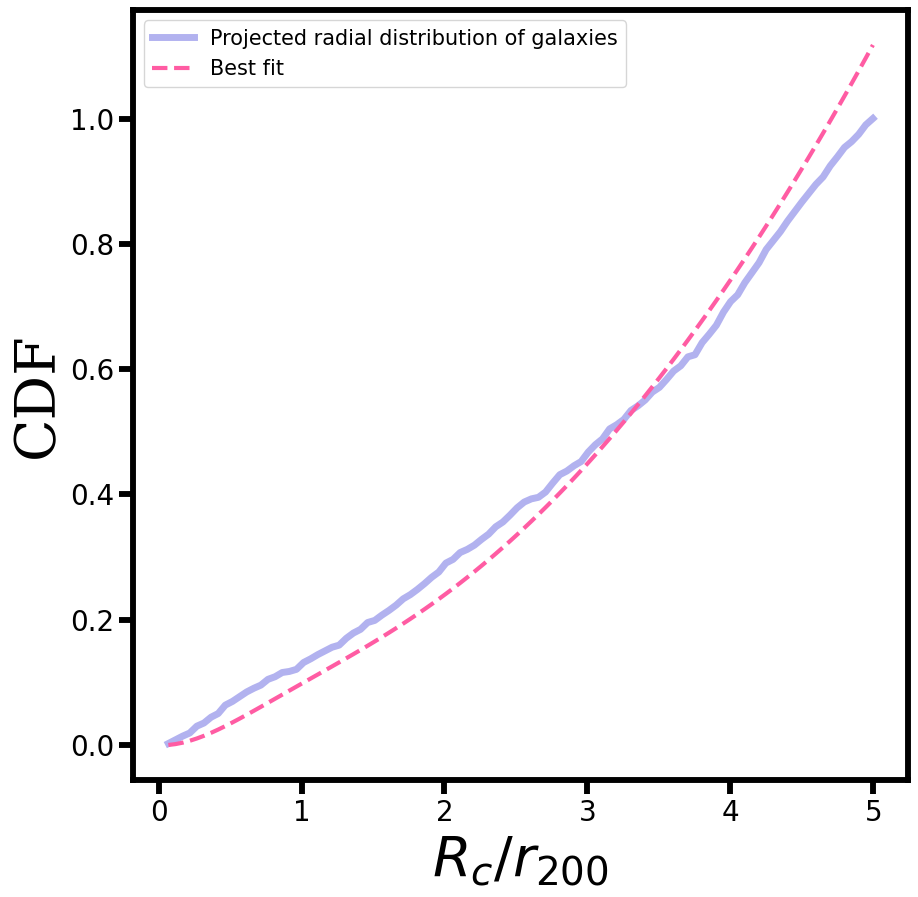

In [17]:
cum_dens = Sersic_density(R, dR, [0.5, r200_deg, 1.0, 1*r200_deg, 2, 0.13]) #initial guess for [Sigma0, R0, alpha, Rt, tau, Sigma_field], same for all clusters

rcParams["font.size"] = 20
rcParams["axes.labelsize"] = 20
rcParams["xtick.labelsize"] = 20
rcParams["ytick.labelsize"] = 20
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(111)   
ax.plot(R/r200_deg, Fz, lw=5.0, c=colors3[1], label="Projected radial distribution of galaxies", alpha=0.3)
ax.plot(Rcz[1:]/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c=colors3[5])
ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
ax.set_ylabel("CDF", fontdict=font)
ax.legend(fontsize=15)

In [ ]:
nsteps = 10000
nwalkers = 32
burn_in = 0.2

labels = [r"$\Sigma_0$", r"$R_0$", r"$\alpha$", r"$R_t$", r"$\tau$", r"$\Sigma_{field}$"]

cl_name_list = []
Sigma0_list = []
R0_list = []
alpha_list = []
Rt_list = []
tau_list = []
Sigma_field_list = []
Rsp_list = []
e_list = []  

cl_names = ["A133", "A463", "A957", "A970", "A978", "A993", "A1069", "A1631", "A1644", "A2415", "A2734", "A3104", "A3112", 
            "A3122", "A3809", "MCXCJ0340-4542", "WHLJ012023-000444", "[YMV2007]514", "[YMV2007]841", "[YMV2007]1540"]

for cl_name in cl_names:

    print("COMPUTING FOR CLUSTER", cl_name)

    t_members = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
    members = t_members["flag_member_photz1"] == 0
    ras = t_members["ra"][members].values
    decs = t_members["dec"][members].values

    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")
    ra0 = clusters_properties["R.A."][clusters_properties["Cluster"] == cl_name].values[0]
    dec0 = clusters_properties["Dec."][clusters_properties["Cluster"] == cl_name].values[0]
    r200_mpc = clusters_properties["R200"][clusters_properties["Cluster"] == cl_name].values[0]
    z_cluster = clusters_properties["z"][clusters_properties["Cluster"] == cl_name].values[0]

    kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
    r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg


    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, ra0, dec0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    #======================================
    #GUESSING PARAMETERS WITH MCMC
    #======================================

    first_guess = np.array([0.5, 1.0*r200_deg, 1.0, 1*r200_deg, 2, 0.13]) #initial guess for [Sigma0, R0, alpha, Rt, tau, Sigma_field], same for all clusters

    sampler = run_mcmc(nsteps, 
                        nwalkers,
                        first_guess,
                        log_probability, 
                        args=(R, dR, Fz, r200_deg), 
                        moves=emcee.moves.StretchMove(),
                        multi_process=False)

    samples = sampler.get_chain()

    #flat = flatten the chains across the ensample
    #discard = discard the burn_in phase
    #thin = "thins" the sample every N iterations (for instance 15)
    flat_samples = sampler.get_chain(discard=int(nsteps*burn_in), thin=15, flat=True)
    means = np.mean(flat_samples, axis=0)

    
    fig, axes = plt.subplots(6, figsize=(10, 15), sharex=True)
    # Styling
    rcParams["font.size"] = 10
    rcParams["axes.labelsize"] = 10
    rcParams["xtick.labelsize"] = 10
    rcParams["ytick.labelsize"] = 10

    for i in range(len(first_guess)):
        ax = axes[i]
        ax.plot(samples[:, :, i], "blue", alpha=0.3)
        ax.axhline(np.median(samples[int(burn_in*nsteps):, :, i]), color="red", lw=2.0)
        ax.set_xlim(0, len(samples))
        ax.set_ylabel(labels[i], fontdict=font)
        ax.yaxis.set_label_coords(-0.1, 0.5)

        # print(np.median(samples[int(burn_in*nsteps):, :, i]))

    axes[-1].set_xlabel("step number", fontdict=font);

    plt.savefig("../figures/SCALE/bootstrap_results_08022026/Sersic/trace_plot_mcmc_cluster_{}.png".format(cl_name),
                                         dpi='figure', format='png')

    #Guess after running the mcmc (median of parameters with 20% burn-in)
    second_guess = np.array([np.median(samples[int(burn_in*nsteps):, :, i]) for i in range(0, 6)])

    #======================================
    #MINIMIZING CHI2 TO FIND BEST FIT
    #======================================
    fit = fit_cumulative(R, dR, Fz, second_guess, r200_deg)
    Rsp = splashback_radius(R, dR, fit.x, Sersic_density)
    e = ellipticity(Rp, Rsp, ras, decs, ra0, dec0)

    cum_dens = Sersic_density(R, dR, fit.x)

    # Run bootstrap
    t0 = time.time()
    nboot = 1000
    boot_results = bootstrap_fit(all_galaxies, fit.x, r200_deg, ra0, dec0, B=nboot)
    print("Bootstrap time taken:", time.time() - t0)
    boot_results.to_csv("tables/SCALE/bootstrap_results_08022026/Sersic/boot_results_cluster-{}.csv".format(cl_name), index=False)


    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/SCALE/bootstrap_results_08022026/Sersic/boot_results_outliers_removed_cluster-{}.csv".format(cl_name), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(30, 30))
    for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
        plt.subplot(3, 3, i+1)
        if (col == "R0") | (col == "Rt") | (col == "Rsp"):
            plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        else:
            plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        plt.title(col, fontsize=20) 
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/SCALE/bootstrap_results_08022026/Sersic/boostrap_parameter_distribution_cluster_{}.png".format(cl_name),
                                         dpi='figure', format='png')


    # Plot cumulative density fit and bootstrap results
    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)   
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel("CDF", fontdict=font)

    for _, row in boot_results_outliers_removed.iterrows():
        params = row[:6].values
        cum_model = Sersic_density(R, dR, params)
        ax.plot(R/r200_deg, cum_model, color="gray", alpha=0.1)

    ax.plot(R/r200_deg, Fz, lw=5.0, c="#ff6700", label="Projected radial distribution of galaxies", alpha=1.0)
    ax.plot(R/r200_deg, cum_dens, lw=3.0, ls="--", label="Best fit", c="k")

    ax.legend(fontsize=15)
    plt.savefig("../figures/SCALE/bootstrap_results_08022026/Sersic/cumulative_density_fit_cluster_{}.png".format(cl_name),
                                         dpi='figure', format='png')
    

    #SAVING BEST FIT PARAMETERS
    cl_name_list.append(cl_name)
    Sigma0_list.append(fit.x[0])
    R0_list.append(fit.x[1]) #deg
    alpha_list.append(fit.x[2])
    Rt_list.append(fit.x[3]) #deg
    tau_list.append(fit.x[4])
    Sigma_field_list.append(fit.x[5]) 
    Rsp_list.append(Rsp) #deg
    e_list.append(e)
    
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/i_mock_list", cl_name_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/Sigma0_list", Sigma0_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/R0_list", R0_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/alpha_list", alpha_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/Rt_list", Rt_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/tau_list", tau_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/Sigma_field_list", Sigma_field_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/Rsp_list", Rsp_list)
    np.save("tables/SCALE/bootstrap_results_08022026/Sersic/e_list", e_list)

### Re-running Rsp

##### Mocks

In [ ]:
nboot = 1000

Rsp_list = []
e_list = []

for i_mock in np.arange(0, 50, 1):

    print("#COMPUTING FOR MOCK CLUSTER ", i_mock)

    t = pd.read_csv("tables/testing-on-mocks/membership-mock-clusters/23-07-2025/cluster-mock_{}_membership.csv".format(i_mock))
    members = t["phot_member"] == 1
    ras = np.array(t["RA"][members]) #deg
    decs = np.array(t["DEC"][members]) #deg
    zp = np.array(t["z_phot_pdfs_mock"][members]) #uso os photo-zs que vem da "clonagem" de galáxias do training set
    zs = np.array(t["z_app"][members]) 

    x0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/ra0_list.npy")[i_mock]
    y0 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/dec0_list.npy")[i_mock]
    r200_deg = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_deg_list.npy")[i_mock]
    r200_mpc = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/r200_mpc_list.npy")[i_mock]
    m200 = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/m200_list.npy")[i_mock]
    z_cluster = np.load("tables/testing-on-mocks/mock_clusters_properties/23-07-2025/z_cluster_list.npy")[i_mock]

    side = min(max(ras) - min(ras), max(decs) - min(decs))
    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    Sigma0 = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/Sigma0_list.npy")[i_mock]
    R0 = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/R0_list.npy")[i_mock]
    alpha = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/alpha_list.npy")[i_mock]
    Rt = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/Rt_list.npy")[i_mock]
    tau = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/tau_list.npy")[i_mock]
    Sigma_field = np.load("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/Sigma_field_list.npy")[i_mock]

    best_params = [Sigma0, R0, alpha, Rt, tau, Sigma_field]

    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, x0, y0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)

    Rsp, gamma = splashback_radius(R, r200_deg, best_params, Sersic_density)
    e = ellipticity(Rp, Rsp, ras, decs, x0, y0)

    boot_results = pd.read_csv("tables/testing-on-mocks/bootstrap_results_22-01-2026/Sersic/boot_results_mock{}.csv".format(i_mock))

    Rsp_list_boot = []
    e_list_boot = []

    for n in tqdm.tqdm(range(nboot)):

        resampled_data = resample(all_galaxies)

        x = resampled_data["ras"] 
        y = resampled_data["decs"]

        #I am letting the cluster's center (x0, y0) fixed
        Rp = clustercentric_distance(x, y, x0, y0)
        Hz, Rcz = np.histogram(Rp, bins=100, density=True)
        dR = Rcz[1] - Rcz[0]
        Fz = np.cumsum(Hz)*dR
        R = Rcz[1:]

        params = np.array([boot_results[col][n] for col in boot_results.columns[:-3]])

        Rsp_boot, gamma_boot = splashback_radius(R, r200_deg, params, Sersic_density)
        ax.plot(R/r200_deg, gamma_boot, lw=1.0, c="#9d4edd", alpha=0.5)
        e_boot = ellipticity(Rp, Rsp, x, y, x0, y0)

        Rsp_list_boot.append(Rsp_boot)
        e_list_boot.append(e_boot)

    ax.plot(R/r200_deg, gamma, lw=3.0, c="#04052e")
    ax.axvline(Rsp/r200_deg, lw=3.0, color="black", label=r"$R_{sp}$")
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel(r"$\gamma(R)$", fontdict=font)
    ax.legend(fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/elliptical_profiles_mocks/bootstrap_results_19-02-2026/Sersic/gamma(R)_mock{}.png".format(i_mock), dpi='figure', format='png')


    # SAVING RESULTS
    boot_results["Rsp"] = Rsp_list_boot 
    boot_results["e"] = e_list_boot
    boot_results.to_csv("tables/testing-on-mocks/bootstrap_results_19-02-2026/Sersic/boot_results_mock{}.csv".format(i_mock), index=False)

    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/testing-on-mocks/bootstrap_results_19-02-2026/Sersic/boot_results_outliers_removed_mock{}.csv".format(i_mock), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(30, 30))
    for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
        plt.subplot(3, 3, i+1)
        if (col == "R0") | (col == "Rt") | (col == "Rsp"):
            plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        else:
            plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        plt.title(col, fontsize=20) 
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/elliptical_profiles_mocks/bootstrap_results_19-02-2026/Sersic/boostrap_parameter_distribution_mock{}.png".format(i_mock), dpi='figure', format='png')


    Rsp_list.append(Rsp)
    e_list.append(e)

    np.save("tables/testing-on-mocks/bootstrap_results_19-02-2026/Sersic/Rsp_list", Rsp_list)
    np.save("tables/testing-on-mocks/bootstrap_results_19-02-2026/Sersic/e_list", e_list)
    

##### SCALE

In [ ]:
nboot = 1000

Rsp_list = []
e_list = []

cl_names = ["A133", "A463", "A957", "A970", "A978", "A993", "A1069", "A1631", "A1644", "A2415", "A2734", "A3104", "A3112", 
            "A3122", "A3809", "MCXCJ0340-4542", "WHLJ012023-000444", "[YMV2007]514", "[YMV2007]841", "[YMV2007]1540"]

for cl_name, i in zip(cl_names, range(len(cl_names))):

    print("COMPUTING FOR CLUSTER", cl_name)

    t_members = pd.read_csv("tables/SCALE/membership_tables_05022026/{}_members-05022026.csv".format(cl_name))
    members = t_members["flag_member_photz1"] == 0
    ras = t_members["ra"][members].values
    decs = t_members["dec"][members].values

    all_galaxies = pd.DataFrame({'ras': ras, 'decs': decs})

    clusters_properties = pd.read_csv("tables/SCALE/clusters_properties.csv")
    ra0 = clusters_properties["R.A."][clusters_properties["Cluster"] == cl_name].values[0]
    dec0 = clusters_properties["Dec."][clusters_properties["Cluster"] == cl_name].values[0]
    r200_mpc = clusters_properties["R200"][clusters_properties["Cluster"] == cl_name].values[0]
    z_cluster = clusters_properties["z"][clusters_properties["Cluster"] == cl_name].values[0]

    kpc_scale = cosmo.kpc_proper_per_arcmin(z=z_cluster).value/60.
    r200_deg = r200_mpc * 1000 / (kpc_scale * 3600) #Convert radius from kpc to deg


    Sigma0 = np.load("tables/SCALE/bootstrap_results_08022026/Sersic/Sigma0_list.npy")[i]
    R0 = np.load("tables/SCALE/bootstrap_results_08022026/Sersic/R0_list.npy")[i]
    alpha = np.load("tables/SCALE/bootstrap_results_08022026/Sersic/alpha_list.npy")[i]
    Rt = np.load("tables/SCALE/bootstrap_results_08022026/Sersic/Rt_list.npy")[i]
    tau = np.load("tables/SCALE/bootstrap_results_08022026/Sersic/tau_list.npy")[i]
    Sigma_field = np.load("tables/SCALE/bootstrap_results_08022026/Sersic/Sigma_field_list.npy")[i]

    best_params = [Sigma0, R0, alpha, Rt, tau, Sigma_field]

    #Distribuição cumulativa observada
    Rp = clustercentric_distance(ras, decs, ra0, dec0)
    Hz, Rcz = np.histogram(Rp, bins=100, density=True)
    dR = Rcz[1] - Rcz[0]
    Fz = np.cumsum(Hz)*dR
    R = Rcz[1:]

    fig = plt.figure(figsize=(10, 10))
    ax = fig.add_subplot(111)

    Rsp, gamma = splashback_radius(R, r200_deg, best_params, Sersic_density)
    e = ellipticity(Rp, Rsp, ras, decs, ra0, dec0)

    boot_results = pd.read_csv("tables/SCALE/bootstrap_results_08022026/Sersic/boot_results_cluster-{}.csv".format(cl_name))

    Rsp_list_boot = []
    e_list_boot = []

    for n in tqdm.tqdm(range(nboot)):

        resampled_data = resample(all_galaxies)

        x = resampled_data["ras"] 
        y = resampled_data["decs"]

        #I am letting the cluster's center (ra0, dec0) fixed
        Rp = clustercentric_distance(x, y, ra0, dec0)
        Hz, Rcz = np.histogram(Rp, bins=100, density=True)
        dR = Rcz[1] - Rcz[0]
        Fz = np.cumsum(Hz)*dR
        R = Rcz[1:]

        params = np.array([boot_results[col][n] for col in boot_results.columns[:-3]])

        Rsp_boot, gamma_boot = splashback_radius(R, r200_deg, params, Sersic_density)
        ax.plot(R/r200_deg, gamma_boot, lw=1.0, c="#9d4edd", alpha=0.5)
        e_boot = ellipticity(Rp, Rsp, x, y, ra0, dec0)

        Rsp_list_boot.append(Rsp_boot)
        e_list_boot.append(e_boot)

    ax.plot(R/r200_deg, gamma, lw=3.0, c="#04052e")
    ax.axvline(Rsp/r200_deg, lw=3.0, color="black", label=r"$R_{sp}$")
    ax.set_xlabel(r"$R_c/r_{200}$", fontdict=font)
    ax.set_ylabel(r"$\gamma(R)$", fontdict=font)
    ax.legend(fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/SCALE/bootstrap_results_23022026/Sersic/gamma(R)_cluster{}.png".format(cl_name), dpi='figure', format='png')


    # SAVING RESULTS
    boot_results["Rsp"] = Rsp_list_boot 
    boot_results["e"] = e_list_boot
    boot_results.to_csv("tables/SCALE/bootstrap_results_23022026/Sersic/boot_results_cluster-{}.csv".format(cl_name), index=False)

    # Remove outliers
    z = boot_results
    for col in boot_results.columns:
        Q1 = boot_results[col].quantile(0.25)
        Q3 = boot_results[col].quantile(0.75)
        IQR = Q3 - Q1
        z = z[(z[col] > Q1 - 1.5*IQR) & (z[col] < Q3 + 1.5*IQR)]
        print("Remaining samples after outlier removal:", len(z))
    boot_results_outliers_removed = z
    boot_results_outliers_removed.to_csv("tables/SCALE/bootstrap_results_23022026/Sersic/boot_results_outliers_removed_cluster-{}.csv".format(cl_name), index=False)


    # Plot parameter distributions
    rcParams["font.size"] = 20
    rcParams["axes.labelsize"] = 20
    rcParams["xtick.labelsize"] = 20
    rcParams["ytick.labelsize"] = 20
    plt.figure(figsize=(30, 30))
    for i, col in enumerate(boot_results_outliers_removed.columns):  # exclude chi2
        plt.subplot(3, 3, i+1)
        if (col == "R0") | (col == "Rt") | (col == "Rsp"):
            plt.hist(boot_results_outliers_removed[col]/r200_deg, bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        else:
            plt.hist(boot_results_outliers_removed[col], bins=20, histtype="stepfilled", color=colors3[i], edgecolor="black")
        plt.title(col, fontsize=20) 
        plt.xlabel("parameter value", fontsize=15)
        plt.ylabel("Frequency", fontsize=15)
    plt.tight_layout()
    plt.savefig("../figures/SCALE/bootstrap_results_23022026/Sersic/boostrap_parameter_distribution_cluster{}.png".format(cl_name), dpi='figure', format='png')


    Rsp_list.append(Rsp)
    e_list.append(e)

    np.save("tables/SCALE/bootstrap_results_23022026/Sersic/Rsp_list", Rsp_list)
    np.save("tables/SCALE/bootstrap_results_23022026/Sersic/e_list", e_list)
    

COMPUTING FOR CLUSTER A133


100%|██████████| 1000/1000 [11:13<00:00,  1.48it/s]


Remaining samples after outlier removal: 973
Remaining samples after outlier removal: 937
Remaining samples after outlier removal: 900
Remaining samples after outlier removal: 861
Remaining samples after outlier removal: 783
Remaining samples after outlier removal: 768
Remaining samples after outlier removal: 758
Remaining samples after outlier removal: 754
Remaining samples after outlier removal: 749
COMPUTING FOR CLUSTER A463


 44%|████▍     | 442/1000 [07:19<09:10,  1.01it/s]